# Analysis of results

In [9]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os
import subprocess
import csv

## Bozorth3 impostors vs genuines

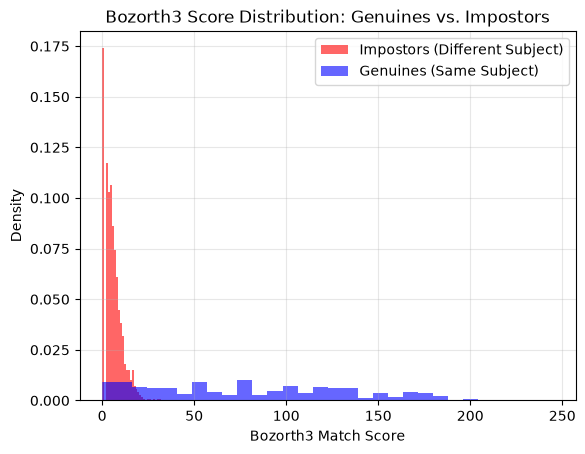

In [7]:
df = pd.read_csv('../bozorth_results.csv')
genuines = df[df['type'] == 'genuine']['score']
impostors = df[df['type'] == 'impostor']['score']

# Plot histograms with transparency to see overlaps
plt.hist(impostors, bins=30, alpha=0.6, color='red', label='Impostors (Different Subject)', density=True)
plt.hist(genuines, bins=30, alpha=0.6, color='blue', label='Genuines (Same Subject)', density=True)

plt.title('Bozorth3 Score Distribution: Genuines vs. Impostors')
plt.xlabel('Bozorth3 Match Score')
plt.ylabel('Density')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

Problematic zone between the score of 0 and 20/25, as genuines can be found there, where ideally it would be impostor zone.

## Similarity matrix

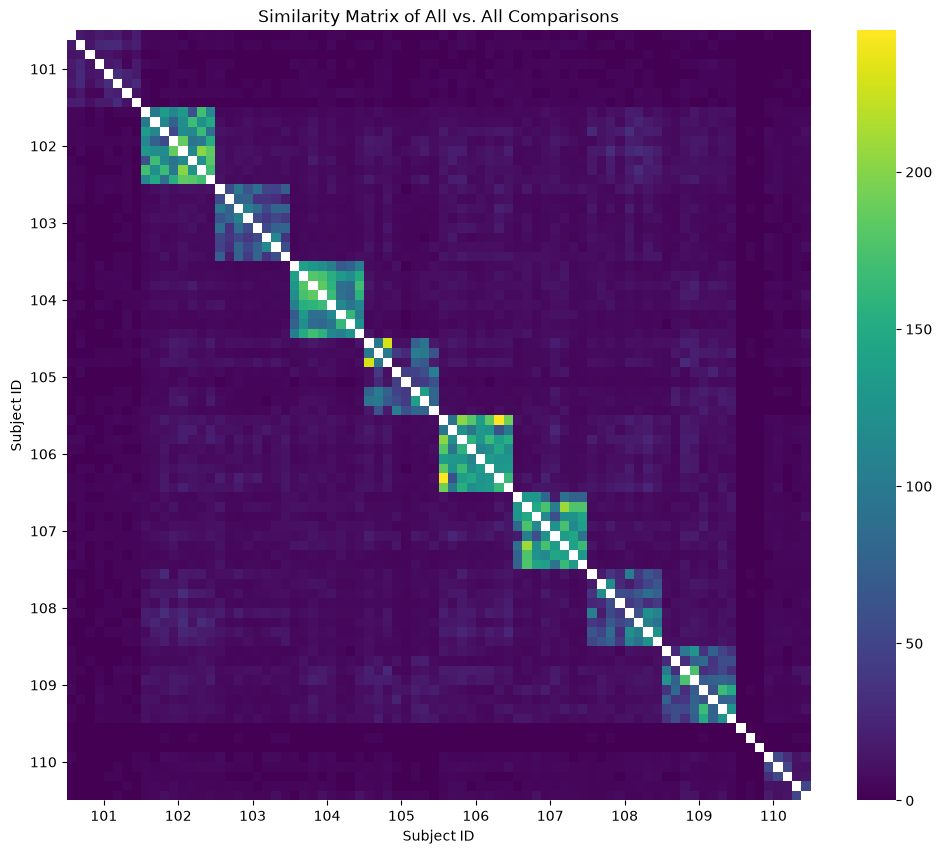

In [8]:
all_images = sorted(list(set(df['img1'].unique().tolist() + df['img2'].unique().tolist())))

# Initialize an empty matrix (DataFrame) filled with NaNs
matrix = pd.DataFrame(index=all_images, columns=all_images, dtype=float)

# Fill the matrix with the bozorth3 scores
for _, row in df.iterrows():
    matrix.at[row['img1'], row['img2']] = row['score']
    # Mirror the score so the matrix is symmetrical for visualization
    matrix.at[row['img2'], row['img1']] = row['score'] 

plt.figure(figsize=(12, 10))

# Turn off Seaborn's default labels so we can apply custom centered ones
sns.heatmap(matrix, cmap='viridis', xticklabels=False, yticklabels=False)

# Calculate center positions for each of the 10 subjects (blocks of 8)
# The centers will be at indices 4, 12, 20... up to 76
tick_positions = np.arange(4, 80, 8)

# Extract just the subject ID (e.g., "101") for each of those positions
subject_labels = [all_images[i].split('_')[0] for i in tick_positions]

# Apply the custom ticks to the axes
plt.xticks(tick_positions, subject_labels, rotation=0, fontsize=10)
plt.yticks(tick_positions, subject_labels, rotation=0, fontsize=10)

plt.title('Similarity Matrix of All vs. All Comparisons')
plt.xlabel('Subject ID')
plt.ylabel('Subject ID')
plt.show()

Fingerprint 101 and 110 are problematic, since the images fail to reflect similarity.

## NFIQ quality analysis

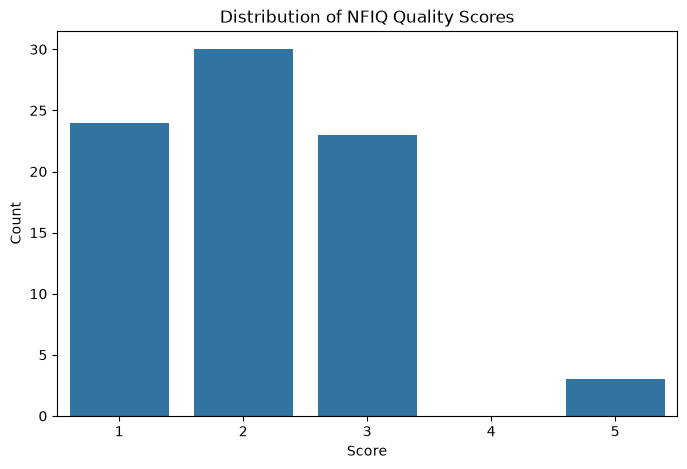

In [12]:
df_quality = pd.read_csv('../nfiq_quality_scores.csv')

plt.figure(figsize=(8, 5))
sns.countplot(data=df_quality, x='nfiq_quality_score', order=[1,2,3,4,5])
plt.title('Distribution of NFIQ Quality Scores')
plt.xlabel('Score')
plt.ylabel('Count')
plt.show()

In [13]:
df_bad = df_quality[df_quality['nfiq_quality_score'] == 5]
print(df_bad)

        image  nfiq_quality_score
72  110_1.png                   5
73  110_2.png                   5
74  110_3.png                   5


All of the poorest quality images are of finger 110, which explains the poor performance seen in similarity matrix. Overall the dataset seems reasonably well captured.

## Bozorth3 treshold finding

Looking at the bozorth3 score distribution, my guess is that optimal treshold would be around 25.

### 1) EER approach

In [27]:
tresholds = []
for i in range(0, 40, 1):
    tresholds.append(i)

print(tresholds)

impostors = df[df["type"] == "impostor"]
genuines = df[df["type"] == "genuine"]
print(len(impostors))
print(len(genuines))

FAR_results = []
for treshold in tresholds:
    FAR = len(impostors[impostors["score"] >= treshold]) / len(impostors)
    FAR_results.append(FAR)

FRR_results = []
for treshold in tresholds:
    FRR = len(genuines[genuines["score"] < treshold]) / len(genuines)
    FRR_results.append(FRR)

print(FAR_results)
print(FRR_results)

[0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39]
2880
280
[1.0, 0.8145833333333333, 0.8145833333333333, 0.8145833333333333, 0.6892361111111112, 0.5791666666666667, 0.465625, 0.3736111111111111, 0.29409722222222223, 0.22881944444444444, 0.18125, 0.140625, 0.10659722222222222, 0.08715277777777777, 0.07083333333333333, 0.05486111111111111, 0.044097222222222225, 0.034027777777777775, 0.027777777777777776, 0.02013888888888889, 0.01423611111111111, 0.009722222222222222, 0.006944444444444444, 0.005208333333333333, 0.004166666666666667, 0.0038194444444444443, 0.002777777777777778, 0.0020833333333333333, 0.0020833333333333333, 0.001388888888888889, 0.001388888888888889, 0.0006944444444444445, 0.00034722222222222224, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0]
[0.0, 0.05714285714285714, 0.05714285714285714, 0.05714285714285714, 0.06785714285714285, 0.07142857142857142, 0.07142857142857142, 0.071428571428

FRR rises as treshold grows, FAR falls as treshold grows

In [28]:
far_arr = np.array(FAR_results)
frr_arr = np.array(FRR_results)

diff = np.abs(far_arr - frr_arr)
EER_idx = np.argmin(diff)

best_treshold = tresholds[EER_idx]
EER = (far_arr[EER_idx] + frr_arr[EER_idx]) / 2

print("Best treshold value, based on EER: ", best_treshold)
print(f"EER: {EER:.4f}")

Best treshold value, based on EER:  12
EER: 0.1051


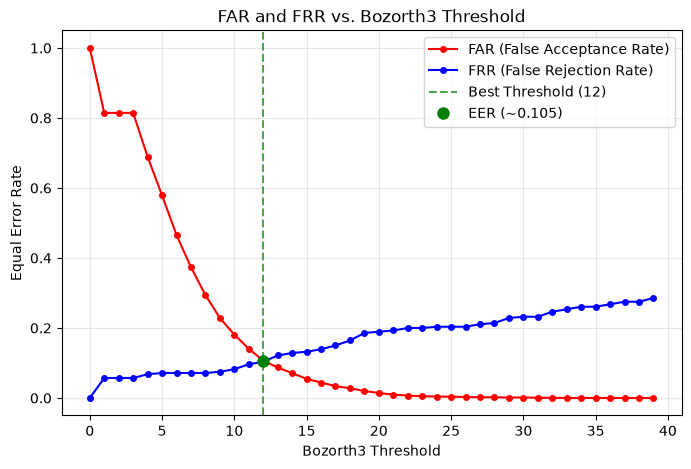

In [30]:
plt.figure(figsize=(8, 5))
plt.plot(tresholds, far_arr, label='FAR (False Acceptance Rate)', color='red', marker='o', markersize=4)
plt.plot(tresholds, frr_arr, label='FRR (False Rejection Rate)', color='blue', marker='o', markersize=4)

# Highlight the EER point
plt.axvline(x=best_treshold, color='green', linestyle='--', alpha=0.7, label=f'Best Threshold ({best_treshold})')
plt.plot(best_treshold, EER, 'go', markersize=8, label=f'EER (~{EER:.3f})')

plt.title('FAR and FRR vs. Bozorth3 Threshold')
plt.xlabel('Bozorth3 Threshold')
plt.ylabel('Equal Error Rate')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

It turns out that treshold = 25, is too high, since it is too strict meaning too many matches are classified as impostors. If we want to optimize the EER best treshold value is 12. However for critical systems, where false positives are costly, a stricter (higher) score should be chosen.

### 2) Bayesian approach

In [35]:
from scipy.stats import gamma, expon

Genuine Gamma Fit: shape=0.70, scale=116.33
Impostor Exponential Fit: scale=5.90
Optimal Bayesian Threshold: 16.54


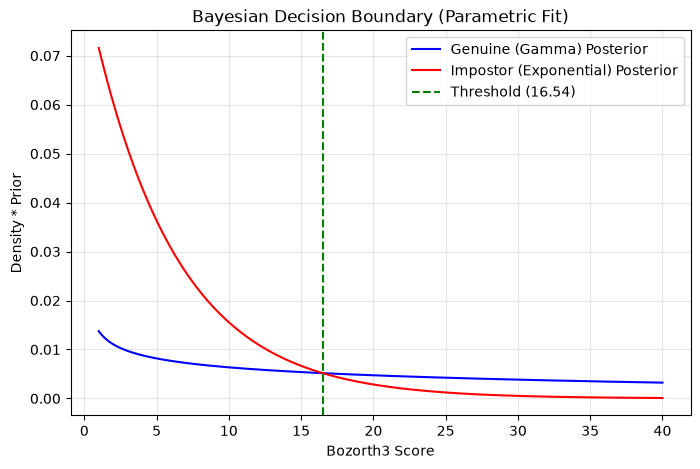

In [38]:
shape_genuine, loc_genuine, scale_genuine = gamma.fit(genuines['score'], floc=-0.001)  # Force the location parameter to be 0 for the gamma distribution

loc_impostor, scale_impostor = expon.fit(impostors['score'], floc=0)  # Force the location parameter to be 0 for the exponential distribution

#PRIORS, eval range
p_g = 0.50
p_i = 0.50
scores = np.linspace(1, 40, 400)

# likelihoods using fitted PDFs
likelihood_genuine = gamma.pdf(scores, shape_genuine, loc=loc_genuine, scale=scale_genuine)
likelihood_impostor = expon.pdf(scores, loc_impostor, scale_impostor)

#Unnormalized posteriors
post_g = likelihood_genuine * p_g
post_i = likelihood_impostor * p_i

#intersection treshold
diff = np.abs(post_g - post_i)
optimal_idx = np.argmin(diff)
optimal_treshold = scores[optimal_idx]

print(f"Genuine Gamma Fit: shape={shape_genuine:.2f}, scale={scale_genuine:.2f}")
print(f"Impostor Exponential Fit: scale={scale_impostor:.2f}")
print(f"Optimal Bayesian Threshold: {optimal_treshold:.2f}")

# Plot the intersection
plt.figure(figsize=(8, 5))
plt.plot(scores, post_g, label='Genuine (Gamma) Posterior', color='blue')
plt.plot(scores, post_i, label='Impostor (Exponential) Posterior', color='red')
plt.axvline(optimal_treshold, color='green', linestyle='--', label=f'Threshold ({optimal_treshold:.2f})')
plt.title('Bayesian Decision Boundary (Parametric Fit)')
plt.xlabel('Bozorth3 Score')
plt.ylabel('Density * Prior')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

### 3) Empirical approach

Best Empirical Threshold: 26
Highest Classification Accuracy: 0.9794


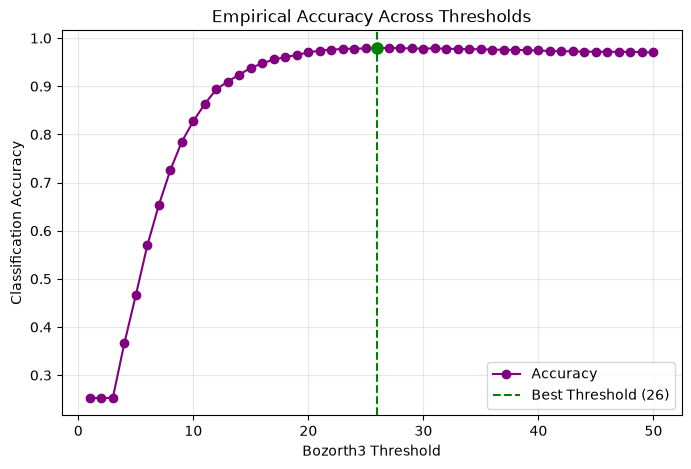

In [39]:
thresholds = np.arange(1, 51)
accuracies = []

# Total comparisons (should be 3160)
total_comparisons = len(genuines) + len(impostors)

for t in thresholds:
    # Count correctly classified pairs
    true_positives = np.sum(genuines['score'] >= t)
    true_negatives = np.sum(impostors['score'] < t)
    
    # Accuracy = (TP + TN) / Total
    accuracy = (true_positives + true_negatives) / total_comparisons
    accuracies.append(accuracy)

# Identify the threshold with the highest accuracy
best_idx = np.argmax(accuracies)
best_threshold = thresholds[best_idx]
best_accuracy = accuracies[best_idx]

print(f"Best Empirical Threshold: {best_threshold}")
print(f"Highest Classification Accuracy: {best_accuracy:.4f}")

plt.figure(figsize=(8, 5))
plt.plot(thresholds, accuracies, marker='o', color='purple', label='Accuracy')
plt.axvline(best_threshold, color='green', linestyle='--', label=f'Best Threshold ({best_threshold})')
plt.plot(best_threshold, best_accuracy, 'go', markersize=8)

plt.title('Empirical Accuracy Across Thresholds')
plt.xlabel('Bozorth3 Threshold')
plt.ylabel('Classification Accuracy')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()